# Distribuciones de las propiedades modales del puente Z24 (EMS)

Este notebook parte de las propiedades modales identificadas en `z24_natural_frequencies_ems.ipynb` (frecuencias naturales y formas modales de los modos 1, 2 y 3 en cada medición horaria del EMS) para estudiar la distribución de cada variable.

**Índice**
1. [Datos de entrada](#sec1)
2. [Efecto de la temperatura en las frecuencias del puente sano](#sec2)
3. [Análisis bivariado de las frecuencias naturales](#sec3)
4. [Normalización de las frecuencias por temperatura](#sec4)

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.colors import TwoSlopeNorm

CACHE_DIR = Path("cache")
RESULTS_DIR = Path("results")

CHANNELS = ["03", "05", "06", "07", "12", "14", "16"]   # same channels as in z24_natural_frequencies_ems.ipynb
MODE_BANDS = {1: (3.5, 4.55), 2: (4.55, 5.9), 3: (9.3, 11.3)}   # search band of each mode (Hz), same notebook
PREP_START = pd.Timestamp("1998-08-05")            # installation of the pier lowering system starts (after reference 1, PDT scenario 01)
DAMAGE_START = pd.Timestamp("1998-08-11 13:15")    # first pier lowering (Table 8, Appendix F of C11)
SENTINEL_ABS = 100.0        # env values with |x| >= this are logger error codes (3276.7, -242.7, -244.3)

# To number the tables and figures automatically
t_num = 0
f_num = 0
eq_num = 0

# Function to display a DataFrame as a table with a caption and optional formatting
def show_table(df, number, caption, precision=2, hide_index=False, n_rows=None):
    display(Markdown(f"**Tabla {number}.** {caption}"))

    # Truncate table (for long DataFrames)
    if n_rows is not None and len(df) > 2 * n_rows:
        ellipsis_row = pd.DataFrame([["..."] * df.shape[1]], columns=df.columns, index=["..."])
        df = pd.concat([df.head(n_rows), ellipsis_row, df.tail(n_rows)])

    styled = df.style.format(precision=precision)
    display(styled.hide(axis="index") if hide_index else styled)

# Function to display a figure with its caption below it
def show_figure(fig, number, caption):
    display(fig)
    plt.close(fig)
    display(Markdown(f"**Figura {number}.** {caption}"))

---
<a id="sec1"></a>
## 1. Datos de entrada

Se cargan dos archivos generados por `z24_natural_frequencies_ems.ipynb`:

- **`results/ems_natural_frequencies.csv`:** una fila por medición, con la fecha (`start`), si es del periodo sano (`healthy`), la frecuencia de cada modo (`f1`, `f2`, `f3`, en Hz) y su MAC con la forma de referencia (`mac1`, `mac2`, `mac3`).
- **`cache/ems_fdd.npz`:** el primer vector singular $\mathbf{u}_1$ de cada medición en cada frecuencia de la banda de cada modo.

Ese notebook no guarda la forma modal de cada medición, así que aquí se toma de la cache: es $\mathbf{u}_1$ en la frecuencia del pico identificado. Como $\mathbf{u}_1$ es complejo y su fase es arbitraria, cada forma se gira para alinearla con la forma media del periodo sano, se toma la parte real y se escala para que su mayor componente valga 1 en valor absoluto.

Las formas salen de los canales normalizados (Ec. 2 de `z24_natural_frequencies_ems.ipynb`): describen el modo en esos 7 sensores, pero no son las formas modales físicas del puente.

In [2]:
modal = pd.read_csv(RESULTS_DIR / "ems_natural_frequencies.csv", parse_dates=["start"])

cache = np.load(CACHE_DIR / "ems_fdd.npz")
f = cache["f"]
order = np.argsort(cache["start"])                       # same order as the CSV (by start time)
assert (cache["code"][order] == modal["code"].to_numpy()).all()

for m, (lo, hi) in MODE_BANDS.items():
    fb = f[(f >= lo) & (f <= hi)]
    rows = np.flatnonzero(modal[f"f{m}"].notna())       # measurements where the mode was identified
    k = np.rint((modal.loc[rows, f"f{m}"].to_numpy() - fb[0]) / (f[1] - f[0])).astype(int)   # peak bin
    phi = cache[f"u1_{m}"][order][rows, k]               # complex singular vector at the peak

    # Align the phase with the mean healthy shape, keep the real part and scale to max |component| = 1
    healthy = modal.loc[rows, "healthy"].to_numpy()
    ref = np.linalg.svd(phi[healthy], full_matrices=False)[2][0].conj()
    rot = phi @ ref.conj()
    phi = np.real(phi * (np.conj(rot) / np.abs(rot))[:, None])
    phi /= np.abs(phi).max(axis=1, keepdims=True)

    for j, ch in enumerate(CHANNELS):
        modal[f"phi{m}_{ch}"] = np.nan
        modal.loc[rows, f"phi{m}_{ch}"] = phi[:, j]

print(f"{len(modal)} measurements, from {modal['start'].min()} to {modal['start'].max()}")
print(f"Healthy: {modal['healthy'].sum()} | damage period: {(~modal['healthy']).sum()}")

t_num += 1
show_table(modal, t_num, "Propiedades modales de cada medición del EMS (primeras y últimas filas): frecuencia (`f`), "
           "MAC con la forma de referencia (`mac`) y componente de la forma modal en cada canal (`phi<modo>_<canal>`).",
           precision=3, n_rows=5)

5653 measurements, from 1997-11-10 14:00:13 to 1998-09-10 13:00:10
Healthy: 4979 | damage period: 674


**Tabla 1.** Propiedades modales de cada medición del EMS (primeras y últimas filas): frecuencia (`f`), MAC con la forma de referencia (`mac`) y componente de la forma modal en cada canal (`phi<modo>_<canal>`).

,code,start,healthy,f1,mac1,f2,mac2,f3,mac3,phi1_03,phi1_05,phi1_06,phi1_07,phi1_12,phi1_14,phi1_16,phi2_03,phi2_05,phi2_06,phi2_07,phi2_12,phi2_14,phi2_16,phi3_03,phi3_05,phi3_06,phi3_07,phi3_12,phi3_14,phi3_16
0,01C14,1997-11-10 14:00:13,True,3.983,0.907,5.131,0.890,9.651,0.731,0.735,-0.885,1.000,-0.138,0.850,0.184,-0.008,0.591,-0.429,-0.525,-0.366,-0.230,-1.000,0.941,0.738,0.696,-0.920,0.172,-1.000,0.028,0.040
1,01C15,1997-11-10 15:00:11,True,3.994,0.957,5.170,0.857,9.978,0.771,0.862,-1.000,0.973,0.073,0.954,0.714,-0.336,0.134,-0.277,-0.547,-0.023,-0.449,-0.681,1.000,0.985,1.000,-0.884,0.696,-0.876,-0.236,0.623
2,01C16,1997-11-10 16:00:10,True,3.978,0.995,5.053,0.723,10.106,0.754,0.900,-0.983,1.000,0.073,0.987,0.656,-0.079,0.370,-0.376,-0.460,-0.218,-0.223,-0.955,1.000,0.755,1.000,-0.751,0.810,-0.738,-0.056,0.790
3,01C17,1997-11-10 17:00:10,True,3.975,0.971,4.980,0.779,10.139,0.838,0.688,-1.000,0.957,-0.014,0.951,0.613,-0.314,0.435,-0.066,-0.651,-0.364,-0.644,-0.949,1.000,0.611,1.000,-0.750,0.266,-0.719,-0.232,0.779
4,01C18,1997-11-10 18:00:10,True,3.958,0.946,nan,nan,10.251,0.816,0.888,-1.000,0.737,-0.097,0.925,0.417,0.085,nan,nan,nan,nan,nan,nan,nan,0.862,1.000,-0.878,0.604,-0.838,-0.420,0.840
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5648,44F09,1998-09-10 09:00:10,False,3.844,0.931,4.667,0.968,9.671,0.887,0.962,-1.000,0.973,-0.241,0.973,0.310,-0.132,0.799,-0.861,-0.945,-0.461,-0.940,-0.982,1.000,0.749,1.000,-0.484,0.287,-0.468,-0.367,0.417
5649,44F10,1998-09-10 10:00:10,False,3.846,0.899,4.679,0.970,9.783,0.774,0.964,-1.000,0.964,-0.318,0.962,0.240,-0.083,0.750,-0.713,-1.000,-0.472,-0.989,-0.957,0.978,0.798,1.000,-0.382,0.061,-0.377,0.149,0.423
5650,44F11,1998-09-10 11:00:10,False,3.838,0.944,4.656,0.956,9.745,0.876,0.960,-1.000,0.978,-0.219,0.979,0.365,-0.187,0.693,-0.868,-0.978,-0.361,-0.974,-1.000,0.998,0.622,1.000,-0.553,0.444,-0.524,-0.075,0.298
5651,44F12,1998-09-10 12:00:10,False,3.840,0.917,4.704,0.963,9.742,0.724,0.973,-1.000,0.967,-0.293,0.969,0.279,-0.088,0.825,-0.767,-0.947,-0.545,-0.942,-0.962,1.000,0.654,1.000,-0.345,0.276,-0.335,-0.126,0.473


---
<a id="sec2"></a>
## 2. Efecto de la temperatura en las frecuencias del puente sano

La temperatura de cada medición se toma de `cache/ems_inventory.csv` (generado en `z24_data_structure.ipynb`): el promedio de la lectura ambiental tomada justo antes de las aceleraciones (PRE).

Se usa la **temperatura del pavimento**: el promedio de `TP1` y `TP2` (secciones 1 y 2 del tablero), en °C. Se elige porque:
- tiene datos en todas las horas del periodo sano;
- es la que más se correlaciona con las frecuencias (las temperaturas del tablero dan resultados parecidos; la del aire, `AT`, algo menos);
- la literatura del Z24 atribuye la subida de las frecuencias con el frío a la rigidización del asfalto.

**Preparación del daño.** Antes del primer descenso de la pila se instaló el sistema para bajarla. Las fechas se acotan con los informes de los ensayos PDT (`.DOC` dentro de `pdt_01-08.zip`) y los apéndices del informe:

**Tabla 2.** Fechas de la preparación del daño.

| Fecha | Qué pasó | Fuente |
|---|---|---|
| 04–05.08.1998 | Referencia 1 (escenario 01): puente sano, sin el sistema | `168'349_701A.DOC` |
| 05–10.08.1998 | Instalación del sistema en la pila Koppigen: se cortan tres tramos de la pila y se reemplazan por piezas de acero con gatos hidráulicos | Apéndice D de `C11-Appendices.pdf` (sin fechas) |
| 09–10.08.1998 | Referencia 2 (escenario 02): sistema instalado, pila sin bajar | `168'349_702A.DOC` |
| 11.08.1998, 13:15 | Primer descenso de la pila (−20 mm): primer daño | Tabla 8 del Apéndice F de `C11-Appendices.pdf` |

La instalación no es un daño, pero cambia la pila. Por eso las mediciones desde el 05.08.1998 hasta el primer descenso se separan del resto del periodo sano (Tabla 3). La Figura 1 las muestra en otro color y la Figura 2 usa solo las mediciones anteriores al 05.08.1998.

**Tabla 3.** Periodos del monitoreo. La preparación del daño va del 05.08.1998 al primer descenso de la pila (11.08.1998, 13:15).

Periodo,Desde,Hasta,Mediciones
Sano,10.11.1997 14:00,04.08.1998 23:00,4821
Preparación del daño,05.08.1998 00:00,11.08.1998 13:00,158
Con daño,11.08.1998 14:00,10.09.1998 13:00,674


Healthy measurements with temperature: 4979 of 4979 | T from -6.7 to 40.4 °C


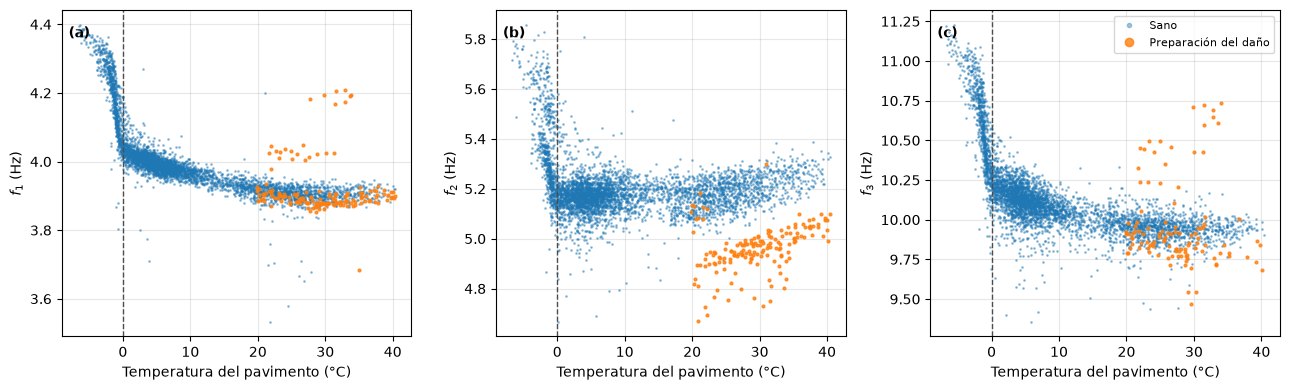

**Figura 1.** Frecuencia natural frente a la temperatura del pavimento en las mediciones anteriores al primer daño: (a) modo 1, (b) modo 2 y (c) modo 3. Azul: puente sano (antes del 05.08.1998); naranja: preparación del daño (05.08.1998 al 11.08.1998, 13:15). La línea discontinua marca 0 °C.

In [3]:
env = pd.read_csv(CACHE_DIR / "ems_inventory.csv", usecols=["code", "TP1", "TP2"])
env[["TP1", "TP2"]] = env[["TP1", "TP2"]].where(env[["TP1", "TP2"]].abs() < SENTINEL_ABS)   # error codes -> NaN
env["T"] = env[["TP1", "TP2"]].mean(axis=1)            # pavement temperature (°C)
modal = modal.merge(env[["code", "T"]], on="code", how="left")

modal["period"] = np.select([modal["start"] < PREP_START, modal["start"] < DAMAGE_START],
                            ["Sano", "Preparación del daño"], "Con daño")

periods = modal.groupby("period", sort=False).agg(Desde=("start", "min"), Hasta=("start", "max"),
                                                  Mediciones=("code", "size")).reset_index()
periods = periods.rename(columns={"period": "Periodo"})
periods[["Desde", "Hasta"]] = periods[["Desde", "Hasta"]].apply(lambda s: s.dt.strftime("%d.%m.%Y %H:%M"))
t_num += 2   # Table 2 is the markdown table of preparation dates above
show_table(periods, t_num, "Periodos del monitoreo. La preparación del daño va del 05.08.1998 al primer descenso de "
           "la pila (11.08.1998, 13:15).", hide_index=True)

healthy = modal[modal["healthy"]]
print(f"Healthy measurements with temperature: {healthy['T'].notna().sum()} of {len(healthy)} | "
      f"T from {healthy['T'].min():.1f} to {healthy['T'].max():.1f} °C")

fig, axes = plt.subplots(1, len(MODE_BANDS), figsize=(13, 4))
for i, (ax, m) in enumerate(zip(axes, MODE_BANDS)):
    for period, color in [("Sano", "C0"), ("Preparación del daño", "C1")]:
        sel = healthy[healthy["period"] == period]
        ax.plot(sel["T"], sel[f"f{m}"], ".", ms=2 if period == "Sano" else 4, alpha=0.4 if period == "Sano" else 0.8,
                color=color, label=period)
    ax.axvline(0, color="0.3", ls="--", lw=1)
    ax.set_xlabel("Temperatura del pavimento (°C)")
    ax.set_ylabel(f"$f_{m}$ (Hz)")
    ax.grid(alpha=0.3)
    ax.text(0.02, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
axes[-1].legend(markerscale=3, fontsize=8, loc="upper right")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Frecuencia natural frente a la temperatura del pavimento en las mediciones anteriores al "
            "primer daño: (a) modo 1, (b) modo 2 y (c) modo 3. Azul: puente sano (antes del 05.08.1998); naranja: "
            "preparación del daño (05.08.1998 al 11.08.1998, 13:15). La línea discontinua marca 0 °C.")

- **Sobre 0 °C:** las frecuencias bajan poco a poco al subir la temperatura (por ejemplo, el modo 1 pasa de unos 4.05 Hz cerca de 0 °C a unos 3.90 Hz sobre 25 °C).
- **Bajo 0 °C:** las frecuencias suben con fuerza (el modo 1 llega a 4.4 Hz, el modo 2 a 5.8 Hz y el modo 3 a 11.1 Hz). El cambio de pendiente en 0 °C es el comportamiento bilineal que reporta la literatura del Z24 (asfalto y suelo congelados).
- **Modo 2:** sobre 0 °C casi no depende de la temperatura. Las mediciones de la preparación del daño (naranja) quedan debajo de la nube del puente sano (4.7 a 5.05 Hz): la instalación del sistema en la pila ya baja la frecuencia del modo 2.
- **Modos 1 y 3 en la preparación:** casi todas las mediciones caen dentro de la nube del puente sano, salvo unas horas con valores anormalmente altos (hasta 4.2 Hz y 10.7 Hz), todas del 06 y 07.08.1998.

La Figura 2 repite la Figura 1 solo con las mediciones del puente sano, anteriores al 05.08.1998.

Measurements before 1998-08-05: 4821 | T from -6.7 to 40.4 °C


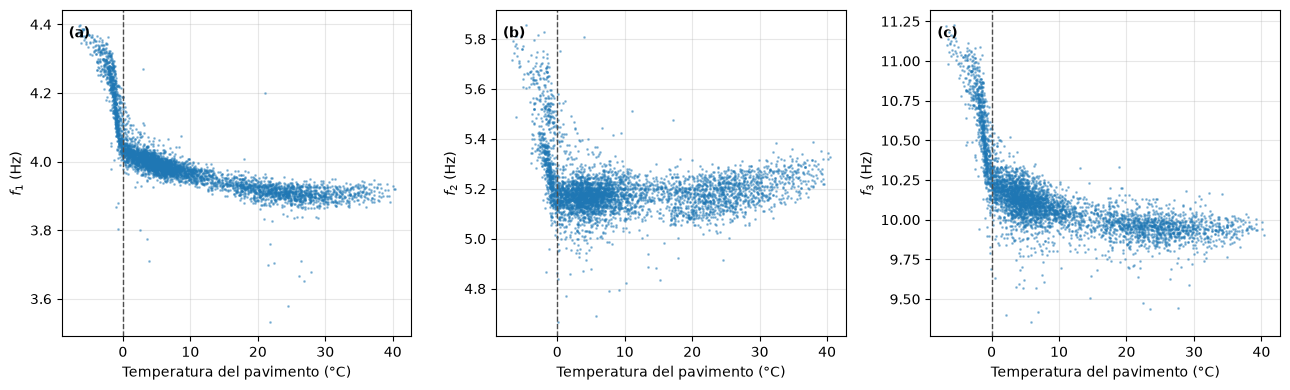

**Figura 2.** Frecuencia natural frente a la temperatura del pavimento en las mediciones del puente sano anteriores al 05.08.1998: (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.

In [4]:
sano = modal[modal["period"] == "Sano"]
print(f"Measurements before {PREP_START.date()}: {len(sano)} | T from {sano['T'].min():.1f} to {sano['T'].max():.1f} °C")

fig, axes = plt.subplots(1, len(MODE_BANDS), figsize=(13, 4))
for i, (ax, m) in enumerate(zip(axes, MODE_BANDS)):
    ax.plot(sano["T"], sano[f"f{m}"], ".", ms=2, alpha=0.4, color="C0")
    ax.axvline(0, color="0.3", ls="--", lw=1)
    ax.set_xlabel("Temperatura del pavimento (°C)")
    ax.set_ylabel(f"$f_{m}$ (Hz)")
    ax.grid(alpha=0.3)
    ax.text(0.02, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Frecuencia natural frente a la temperatura del pavimento en las mediciones del puente sano "
            "anteriores al 05.08.1998: (a) modo 1, (b) modo 2 y (c) modo 3. La línea discontinua marca 0 °C.")

---
<a id="sec3"></a>
## 3. Análisis bivariado de las frecuencias naturales

Prueba de análisis bivariado entre cada par de frecuencias: $(f_1, f_2)$, $(f_1, f_3)$ y $(f_2, f_3)$. Se usan solo las mediciones del puente sano anteriores al 05.08.1998 (sin la preparación del daño), y en cada par solo las mediciones en que se identificaron los dos modos.

La dependencia entre dos frecuencias se mide con dos coeficientes de correlación:

$$
r = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2}\,\sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}
\tag{1}
$$

donde $x_i$ e $y_i$ son las dos frecuencias en la medición $i$, $\bar{x}$ e $\bar{y}$ sus medias y $n$ el número de mediciones. Es el coeficiente de **Pearson**: mide qué tan bien se alinean los puntos en una recta (−1 a 1).

El coeficiente de **Spearman** $\rho_s$ es la Ec. (1) aplicada a los rangos de $x_i$ e $y_i$ (su posición al ordenarlos) en vez de a los valores. Mide si una frecuencia sube cuando la otra sube, aunque la relación no sea una recta, y le afectan menos los valores atípicos.

Como la temperatura cambia las tres frecuencias a la vez y lo hace de forma distinta bajo y sobre 0 °C (sección 2), los coeficientes se calculan con todas las mediciones y por separado para temperaturas del pavimento bajo 0 °C y desde 0 °C.

In [5]:
PAIRS = [(1, 2), (1, 3), (2, 3)]
sano = modal[modal["period"] == "Sano"]

rows = []
for a, b in PAIRS:
    for label, sel in [("Todas", sano), ("T < 0 °C", sano[sano["T"] < 0]), ("T ≥ 0 °C", sano[sano["T"] >= 0])]:
        xy = sel[[f"f{a}", f"f{b}"]].dropna()
        rows.append({"Par": f"f{a} – f{b}", "Mediciones": label, "n": len(xy),
                     "Pearson r": xy.corr(method="pearson").iloc[0, 1],
                     "Spearman ρs": xy.corr(method="spearman").iloc[0, 1]})
corr = pd.DataFrame(rows)

t_num += 1
show_table(corr, t_num, "Coeficientes de correlación entre cada par de frecuencias naturales (puente sano, antes del "
           "05.08.1998), con todas las mediciones y separando por la temperatura del pavimento.", precision=2,
           hide_index=True)

**Tabla 4.** Coeficientes de correlación entre cada par de frecuencias naturales (puente sano, antes del 05.08.1998), con todas las mediciones y separando por la temperatura del pavimento.

Par,Mediciones,n,Pearson r,Spearman ρs
f1 – f2,Todas,4680,0.65,0.27
f1 – f2,T < 0 °C,746,0.80,0.85
f1 – f2,T ≥ 0 °C,3934,0.06,-0.02
f1 – f3,Todas,4659,0.91,0.83
f1 – f3,T < 0 °C,772,0.88,0.91
f1 – f3,T ≥ 0 °C,3887,0.66,0.73
f2 – f3,Todas,4604,0.66,0.28
f2 – f3,T < 0 °C,728,0.78,0.82
f2 – f3,T ≥ 0 °C,3876,0.10,0.00


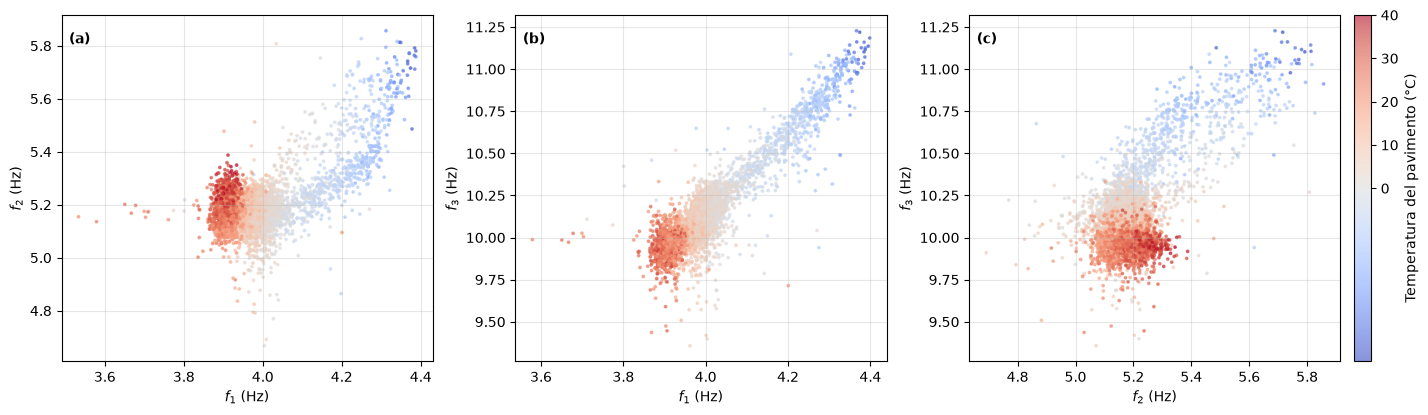

**Figura 3.** Diagramas de dispersión entre cada par de frecuencias naturales (puente sano, antes del 05.08.1998): (a) $f_1$–$f_2$, (b) $f_1$–$f_3$ y (c) $f_2$–$f_3$. El color indica la temperatura del pavimento (blanco en 0 °C; azul bajo 0 °C, rojo sobre 0 °C).

In [6]:
fig, axes = plt.subplots(1, len(PAIRS), figsize=(14, 4.2))
for i, (ax, (a, b)) in enumerate(zip(axes, PAIRS)):
    xy = sano[[f"f{a}", f"f{b}", "T"]].dropna()
    sc = ax.scatter(xy[f"f{a}"], xy[f"f{b}"], c=xy["T"], s=3, alpha=0.6, cmap="coolwarm",
                    norm=TwoSlopeNorm(vmin=-7, vcenter=0, vmax=40))   # white at 0 °C
    ax.set_xlabel(f"$f_{a}$ (Hz)")
    ax.set_ylabel(f"$f_{b}$ (Hz)")
    ax.grid(alpha=0.3)
    ax.text(0.02, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
fig.tight_layout()
fig.colorbar(sc, ax=axes, label="Temperatura del pavimento (°C)", fraction=0.02, pad=0.01)

f_num += 1
show_figure(fig, f_num, "Diagramas de dispersión entre cada par de frecuencias naturales (puente sano, antes del "
            "05.08.1998): (a) $f_1$–$f_2$, (b) $f_1$–$f_3$ y (c) $f_2$–$f_3$. El color indica la temperatura del "
            "pavimento (blanco en 0 °C; azul bajo 0 °C, rojo sobre 0 °C).")

- **Con todas las mediciones** las tres frecuencias están correlacionadas de forma positiva, sobre todo $f_1$ y $f_3$ ($r = 0.91$). Esa correlación la produce casi toda la helada: bajo 0 °C las tres suben juntas y los puntos forman una franja diagonal (azul en la Figura 3).
- **Bajo 0 °C** los tres pares están muy correlacionados ($ho_s$ entre 0.82 y 0.91).
- **Desde 0 °C** solo $f_1$ y $f_3$ siguen correlacionadas ($ho_s = 0.73$): las dos bajan al subir la temperatura. $f_2$ casi no se relaciona con $f_1$ ni con $f_3$ ($ho_s pprox 0$), porque sobre 0 °C el modo 2 casi no depende de la temperatura (sección 2).
- **Para modelar la distribución conjunta:** la dependencia entre las frecuencias no es la misma en todo el rango, cambia con la temperatura. Una distribución conjunta con una sola correlación (por ejemplo, normal bivariada) no la representaría bien; conviene separar por régimen de temperatura o modelar las frecuencias condicionadas a la temperatura.

---
<a id="sec4"></a>
## 4. Normalización de las frecuencias por temperatura

**Objetivo:** llevar todas las mediciones a una misma temperatura de referencia, para comparar el puente sano y el dañado sin el efecto del frío o del calor.

**Pasos:**
1. Ajustar, para cada modo, un modelo de la frecuencia en función de la temperatura con el puente sano (antes del 05.08.1998).
2. Revisar qué tan bien ajusta (residuos).
3. Restar el efecto de la temperatura de cada medición y llevarla a $T_{ref} = 10$ °C.
4. Comparar los periodos sano, preparación y con daño.

### 4.1 Modelo bilineal

La Figura 1 muestra dos rectas unidas en 0 °C: una suave sobre 0 °C y otra muy inclinada bajo 0 °C. El modelo de cada modo $m$ es:

$$
\hat f_m(T) = a_m + b_m\,T + c_m \min(T, 0)
\tag{2}
$$

- $T$: temperatura del pavimento (°C).
- $a_m$: frecuencia en 0 °C, donde se unen las dos rectas (Hz).
- $b_m$: pendiente sobre 0 °C (Hz/°C).
- $b_m + c_m$: pendiente bajo 0 °C (Hz/°C). El término $\min(T, 0)$ vale $T$ bajo 0 °C y 0 sobre 0 °C, así que $c_m$ solo actúa con helada.

Es una regresión lineal con dos variables, $T$ y $\min(T, 0)$, y se ajusta por mínimos cuadrados.

La calidad del ajuste se mide con el residuo $e = f_m - \hat f_m(T)$, la parte de la frecuencia que el modelo no explica:
- $R^2 = 1 - \mathrm{Var}(e)/\mathrm{Var}(f_m)$: fracción de la variación de la frecuencia que explica la temperatura (0 a 1).
- RMSE $= \sqrt{\overline{e^2}}$: error típico del modelo, en Hz.

**Tabla 5.** Coeficientes del modelo bilineal (Ec. 2) de cada modo, ajustado con el puente sano (antes del 05.08.1998), y calidad del ajuste.

Modo,n,a (Hz),b (Hz/°C),b + c (Hz/°C),R²,RMSE (Hz),RMSE T < 0 °C (Hz),RMSE T ≥ 0 °C (Hz)
1,4768,4.0263,-0.0047,-0.0886,0.8622,0.0384,0.0682,0.0289
2,4731,5.1658,0.0010,-0.1138,0.4868,0.0813,0.1318,0.0677
3,4688,10.1834,-0.0096,-0.2208,0.7840,0.1173,0.1827,0.0994


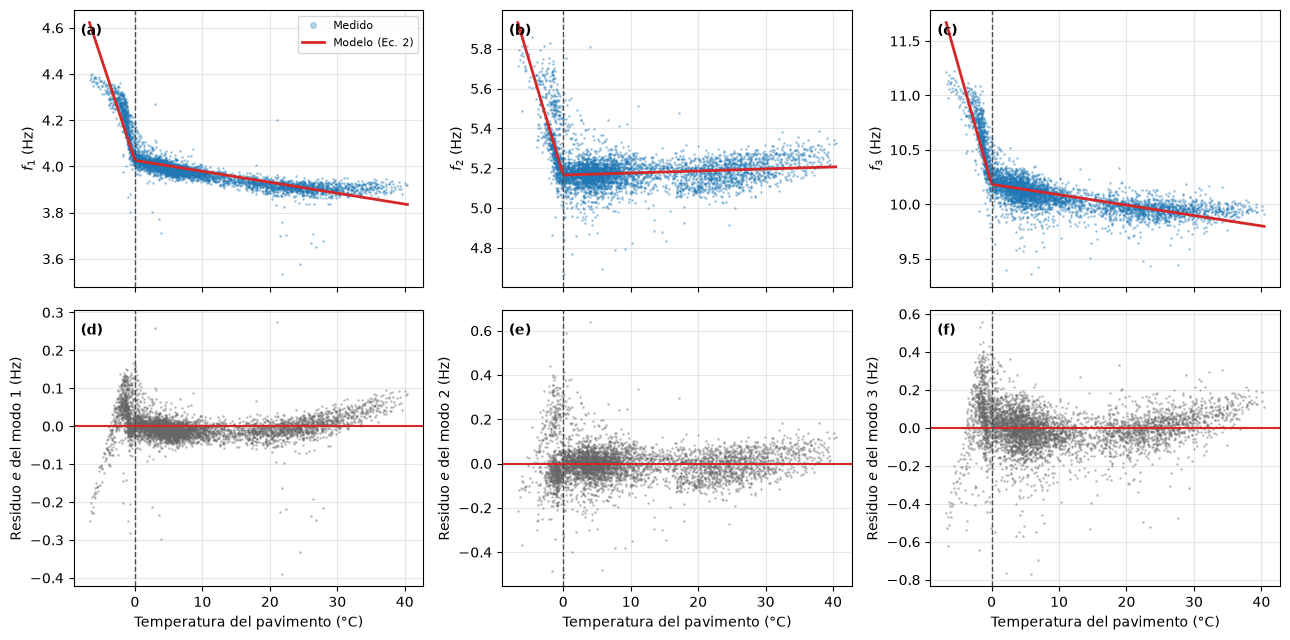

**Figura 4.** Modelo bilineal de cada modo (puente sano, antes del 05.08.1998). Arriba, (a)–(c): frecuencia medida y modelo de los modos 1, 2 y 3. Abajo, (d)–(f): residuo (medido menos modelo). La línea discontinua marca 0 °C.

In [7]:
T_REF = 10.0   # reference temperature for the normalization (°C)


def bilinear_terms(T):
    # Regressors of Eq. 2: intercept, T and min(T, 0)
    T = np.atleast_1d(np.asarray(T, float))
    return np.column_stack([np.ones_like(T), T, np.minimum(T, 0)])


coefs, rows = {}, []
for m in MODE_BANDS:
    d = sano[["T", f"f{m}"]].dropna()
    T, fm = d["T"].to_numpy(), d[f"f{m}"].to_numpy()
    coefs[m], *_ = np.linalg.lstsq(bilinear_terms(T), fm, rcond=None)   # least squares fit of Eq. 2
    e = fm - bilinear_terms(T) @ coefs[m]
    a, b, c = coefs[m]
    rows.append({"Modo": m, "n": len(fm), "a (Hz)": a, "b (Hz/°C)": b, "b + c (Hz/°C)": b + c,
                 "R²": 1 - e.var() / fm.var(), "RMSE (Hz)": np.sqrt(np.mean(e ** 2)),
                 "RMSE T < 0 °C (Hz)": np.sqrt(np.mean(e[T < 0] ** 2)),
                 "RMSE T ≥ 0 °C (Hz)": np.sqrt(np.mean(e[T >= 0] ** 2))})

t_num += 1
show_table(pd.DataFrame(rows), t_num, "Coeficientes del modelo bilineal (Ec. 2) de cada modo, ajustado con el puente "
           "sano (antes del 05.08.1998), y calidad del ajuste.", precision=4, hide_index=True)

T_grid = np.linspace(sano["T"].min(), sano["T"].max(), 200)
fig, axes = plt.subplots(2, len(MODE_BANDS), figsize=(13, 6.5), sharex=True)
for i, m in enumerate(MODE_BANDS):
    d = sano[["T", f"f{m}"]].dropna()
    e = d[f"f{m}"] - bilinear_terms(d["T"]) @ coefs[m]
    ax = axes[0, i]
    ax.plot(d["T"], d[f"f{m}"], ".", ms=2, alpha=0.3, color="C0", label="Medido")
    ax.plot(T_grid, bilinear_terms(T_grid) @ coefs[m], color="C3", lw=2, label="Modelo (Ec. 2)")
    ax.set_ylabel(f"$f_{m}$ (Hz)")
    ax = axes[1, i]
    ax.plot(d["T"], e, ".", ms=2, alpha=0.3, color="0.4")
    ax.axhline(0, color="C3", lw=1.5)
    ax.set_ylabel(f"Residuo $e$ del modo {m} (Hz)")
    ax.set_xlabel("Temperatura del pavimento (°C)")
    for j, ax in enumerate(axes[:, i]):
        ax.axvline(0, color="0.3", ls="--", lw=1)
        ax.grid(alpha=0.3)
        ax.text(0.02, 0.95, f"({chr(97 + i + 3 * j)})", transform=ax.transAxes, va="top", fontweight="bold")
axes[0, 0].legend(markerscale=4, fontsize=8, loc="upper right")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Modelo bilineal de cada modo (puente sano, antes del 05.08.1998). Arriba, (a)–(c): frecuencia "
            "medida y modelo de los modos 1, 2 y 3. Abajo, (d)–(f): residuo (medido menos modelo). La línea discontinua "
            "marca 0 °C.")

- **Sobre 0 °C** el modelo ajusta bien: el RMSE es de 0.03, 0.07 y 0.10 Hz en los modos 1, 2 y 3.
- **Bajo 0 °C** el error es el doble. Hay dos fallas que se ven en los residuos (Figura 4d–f):
  - cerca de 0 °C hay residuos positivos: el puente sigue congelado aunque la temperatura del pavimento ya subió (inercia térmica del suelo y del asfalto);
  - bajo −4 °C la recta predice frecuencias más altas que las medidas: la rigidez deja de crecer al seguir bajando la temperatura.
- **Modo 2:** sobre 0 °C la pendiente es casi cero; por eso su $R^2$ es bajo (0.49): la temperatura explica poco de su variación.

### 4.2 Frecuencias normalizadas

A cada medición se le quita lo que predice el modelo a su temperatura y se le suma lo que predice a $T_{ref}$:

$$
f_m^{norm} = f_m - \hat f_m(T) + \hat f_m(T_{ref})
\tag{3}
$$

- $f_m$: frecuencia medida del modo $m$; $T$: temperatura del pavimento en esa medición.
- $f_m^{norm}$: la frecuencia que se habría medido a $T_{ref} = 10$ °C.

En palabras: $f_m^{norm}$ es el residuo $e$ más un valor fijo, $\hat f_m(T_{ref})$. El modelo se ajusta solo con el puente sano y después se aplica a todas las mediciones, también a las de la preparación y del daño.

**Tabla 6.** Frecuencias medidas (f) y normalizadas a 10 °C (f norm, Ec. 3) en cada periodo.

Modo,Periodo,Media f (Hz),Desv. est. f (Hz),Media f norm (Hz),Desv. est. f norm (Hz)
1,Sano,4.004,0.103,3.979,0.038
1,Preparación del daño,3.919,0.079,4.011,0.081
1,Con daño,3.855,0.046,3.917,0.051
2,Sano,5.203,0.113,5.176,0.081
2,Preparación del daño,4.962,0.094,4.942,0.092
2,Con daño,4.798,0.123,4.783,0.119
3,Sano,10.148,0.252,10.088,0.117
3,Preparación del daño,9.962,0.275,10.129,0.277
3,Con daño,9.749,0.123,9.874,0.118


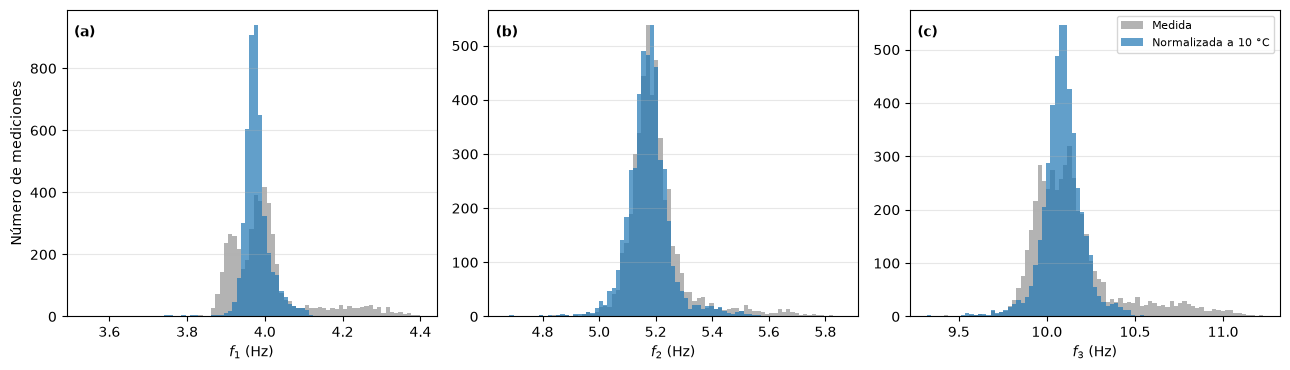

**Figura 5.** Histograma de las frecuencias del puente sano (antes del 05.08.1998), medidas y normalizadas a 10 °C: (a) modo 1, (b) modo 2 y (c) modo 3.

In [8]:
for m in MODE_BANDS:
    T = modal["T"].to_numpy()
    modal[f"fn{m}"] = modal[f"f{m}"] - bilinear_terms(T) @ coefs[m] + (bilinear_terms(T_REF) @ coefs[m])[0]

rows = []
for period in ["Sano", "Preparación del daño", "Con daño"]:
    sel = modal[modal["period"] == period]
    for m in MODE_BANDS:
        rows.append({"Modo": m, "Periodo": period,
                     "Media f (Hz)": sel[f"f{m}"].mean(), "Desv. est. f (Hz)": sel[f"f{m}"].std(),
                     "Media f norm (Hz)": sel[f"fn{m}"].mean(), "Desv. est. f norm (Hz)": sel[f"fn{m}"].std()})
norm_summary = pd.DataFrame(rows).sort_values("Modo", kind="stable")

t_num += 1
show_table(norm_summary, t_num, f"Frecuencias medidas (f) y normalizadas a {T_REF:.0f} °C (f norm, Ec. 3) en cada "
           "periodo.", precision=3, hide_index=True)

sano = modal[modal["period"] == "Sano"]
fig, axes = plt.subplots(1, len(MODE_BANDS), figsize=(13, 3.8))
for i, (ax, m) in enumerate(zip(axes, MODE_BANDS)):
    raw, norm = sano[f"f{m}"].dropna(), sano[f"fn{m}"].dropna()
    bins = np.linspace(min(raw.min(), norm.min()), max(raw.max(), norm.max()), 80)
    ax.hist(raw, bins=bins, color="0.7", label="Medida")
    ax.hist(norm, bins=bins, color="C0", alpha=0.7, label=f"Normalizada a {T_REF:.0f} °C")
    ax.set_xlabel(f"$f_{m}$ (Hz)")
    ax.grid(axis="y", alpha=0.3)
    ax.text(0.02, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
axes[0].set_ylabel("Número de mediciones")
axes[-1].legend(fontsize=8, loc="upper right")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, "Histograma de las frecuencias del puente sano (antes del 05.08.1998), medidas y normalizadas "
            f"a {T_REF:.0f} °C: (a) modo 1, (b) modo 2 y (c) modo 3.")

- La normalización reduce la desviación estándar del puente sano: de 0.103 a 0.038 Hz en el modo 1, de 0.113 a 0.081 Hz en el modo 2 y de 0.252 a 0.117 Hz en el modo 3 (Tabla 6).
- Las colas de frecuencias altas de la helada desaparecen casi del todo (Figura 5): las distribuciones quedan estrechas y con un solo pico.
- **Con daño**, la frecuencia normalizada media baja respecto al puente sano: −1.6 % en el modo 1, −7.6 % en el modo 2 y −2.1 % en el modo 3.

### 4.3 Comparación del puente sano y el dañado

La Figura 6 muestra las frecuencias normalizadas a lo largo del monitoreo. La franja gris es la media del puente sano ± 2 desviaciones estándar: el rango donde cae cerca del 95 % de las mediciones sanas si se distribuyen de forma normal.

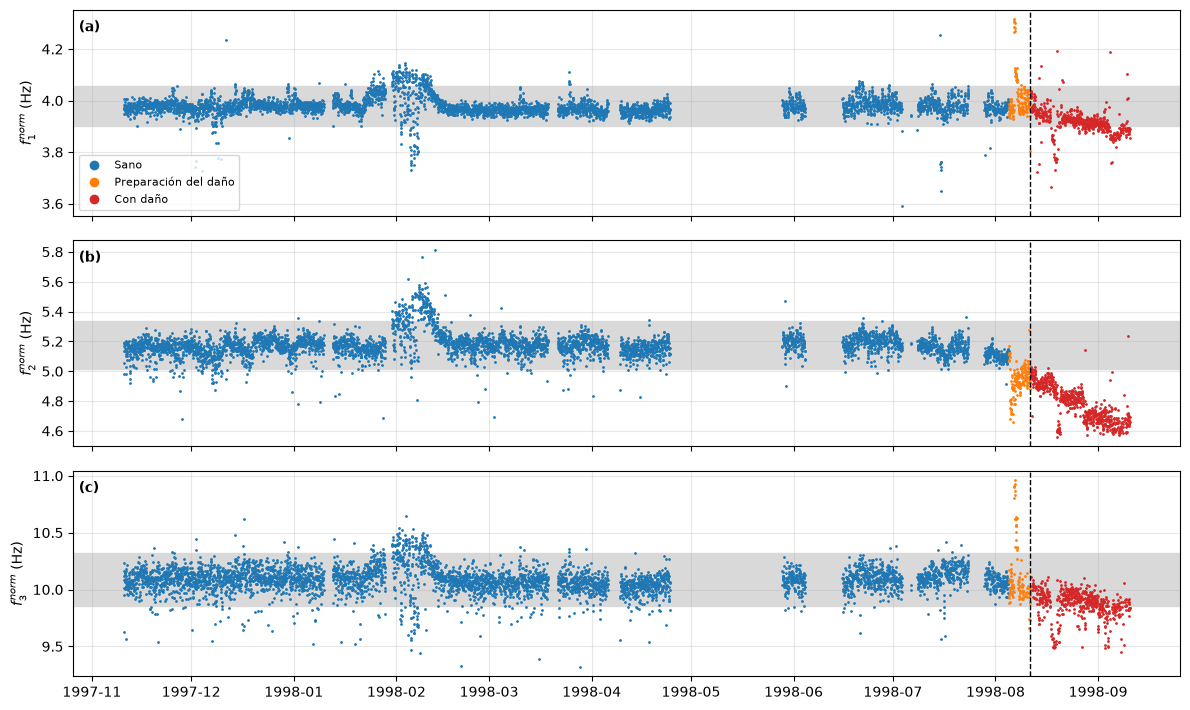

**Figura 6.** Frecuencias normalizadas a 10 °C (Ec. 3) a lo largo del monitoreo: (a) modo 1, (b) modo 2 y (c) modo 3. Franja gris: media del puente sano ± 2 desviaciones estándar. La línea discontinua marca el primer descenso de la pila (11.08.1998).

In [9]:
fig, axes = plt.subplots(len(MODE_BANDS), 1, figsize=(12, 2.4 * len(MODE_BANDS)), sharex=True)
for i, (ax, m) in enumerate(zip(axes, MODE_BANDS)):
    mu, sd = sano[f"fn{m}"].mean(), sano[f"fn{m}"].std()
    ax.axhspan(mu - 2 * sd, mu + 2 * sd, color="0.85", zorder=0)
    for period, color in [("Sano", "C0"), ("Preparación del daño", "C1"), ("Con daño", "C3")]:
        sel = modal[modal["period"] == period]
        ax.plot(sel["start"], sel[f"fn{m}"], ".", ms=2, color=color, label=period)
    ax.axvline(DAMAGE_START, color="k", ls="--", lw=1)
    ax.set_ylabel(f"$f_{m}^{{norm}}$ (Hz)")
    ax.grid(alpha=0.3)
    ax.text(0.005, 0.95, f"({chr(97 + i)})", transform=ax.transAxes, va="top", fontweight="bold")
axes[0].legend(markerscale=6, fontsize=8, loc="lower left")
fig.tight_layout()

f_num += 1
show_figure(fig, f_num, f"Frecuencias normalizadas a {T_REF:.0f} °C (Ec. 3) a lo largo del monitoreo: (a) modo 1, "
            "(b) modo 2 y (c) modo 3. Franja gris: media del puente sano ± 2 desviaciones estándar. La línea "
            "discontinua marca el primer descenso de la pila (11.08.1998).")

- **Puente sano:** el 5 % de las mediciones queda fuera de la franja, como se espera con ± 2 desviaciones estándar. Se concentran en la helada de fines de enero a fines de febrero de 1998, donde el modelo no corrige bien (inercia térmica, sección 4.1).
- **Preparación del daño:** el modo 2 ya sale de la franja por abajo.
- **Con daño** (mediciones bajo la franja):
  - modo 2: el 99 %, desde la primera semana; baja por escalones hasta unos 4.65 Hz;
  - modo 1: el 30 %; sube del 3 % en la primera semana al 82 % en la última;
  - modo 3: el 32 %; cerca del 57 % en las dos últimas semanas.
- **Conclusión:** después de normalizar por temperatura, el daño se distingue con claridad en el modo 2 desde el primer descenso de la pila, y en los modos 1 y 3 recién con los daños de fines de agosto y septiembre. Para mejorar la corrección en la helada habría que agregar al modelo la temperatura de horas o días anteriores.